# Løsningsforslag – arbeidskrav BED-2501, høst 2026

Notebooken regner ut alle tallsvarene i arbeidskravet, seksjon for seksjon, og hører til beamer-presentasjonen av løsningsforslaget. Hver beregning sjekkes mot fasiten med `sjekk()`, som bruker oppgavens toleranse. Kvartiler følger formelarket: medianen av nedre og øvre halvdel.

**Merknader til fasiten** (samme som i presentasjonen):
- Seksjon 14, ett-utvalgs t-test: gjennomsnittet i utvalget er **12.78**, ikke 2.78 (2.7786 er *Mean Difference*).
- Seksjon 13: F-testen har (2, 87) frihetsgrader. Fasitens 89 er total df.
- Seksjon 12: «størst påvirkning» avhenger av enhetene. Kjonn har størst koeffisient, Foreldrehoyde størst t-verdi.
- Seksjon 3: et boksplott viser ikke gjennomsnittet, så «kan ikke avgjøres» er også forsvarlig for gjennomsnitt > median.
- Seksjon 11: «normalitet er oppfylt» er galt fordi utskriften ikke har noen normalitetstest.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

def sjekk(navn, beregnet, fasit, tol=0.0):
    ok = abs(beregnet - fasit) <= tol + 1e-9
    print(f"{'OK ' if ok else 'AVVIK'} {navn:<55} beregnet = {beregnet:.4f}   fasit = {fasit} (±{tol})")
    return ok

## Seksjon 3 – Deskriptiv statistikk
### Del 1: Fem observasjoner: 0, 4, 3, 7, 3
Empirisk varians bruker $n-1$ i nevneren. Første kvartil er etter formelarket medianen av nedre halvdel (medianen utelates når $n$ er odde): nedre halvdel er 0, 3, så $Q_1 = 1.5$.

In [2]:
x = np.array([0, 4, 3, 7, 3])
xs = np.sort(x); n = len(x)
snitt    = x.mean()
typetall = pd.Series(x).mode()[0]
median   = np.median(x)
bredde   = x.max() - x.min()
varians  = x.var(ddof=1)

def kvartiler(xs):
    # Formelarket: medianen av nedre og øvre halvdel, medianen utelates når n er odde
    m = len(xs) // 2
    return np.median(xs[:m]), np.median(xs[-m:])
Q1, Q3 = kvartiler(xs)

print("Sortert:", xs, "| nedre halvdel:", xs[:n // 2], "| Q3 =", Q3)
sjekk("Gjennomsnitt", snitt, 3.4)
sjekk("Typetall", typetall, 3)
sjekk("Median", median, 3)
sjekk("Variasjonsbredde", bredde, 7)
sjekk("Empirisk varians (n-1)", varians, 6.3)
sjekk("Første kvartil", Q1, 1.5)

Sortert: [0 3 3 4 7] | nedre halvdel: [0 3] | Q3 = 5.5
OK  Gjennomsnitt                                            beregnet = 3.4000   fasit = 3.4 (±0.0)
OK  Typetall                                                beregnet = 3.0000   fasit = 3 (±0.0)
OK  Median                                                  beregnet = 3.0000   fasit = 3 (±0.0)
OK  Variasjonsbredde                                        beregnet = 7.0000   fasit = 7 (±0.0)
OK  Empirisk varians (n-1)                                  beregnet = 6.3000   fasit = 6.3 (±0.0)
OK  Første kvartil                                          beregnet = 1.5000   fasit = 1.5 (±0.0)


np.True_

### Del 2: Boksplott
Fem-tallsoppsummeringen leses av plottet: min = 0, Q1 = 1, median = 2, Q3 = 4, maks = 7. Vi tegner et boksplott med samme fem tall for å vise skjevheten.

OK  Kvartilbredde Q3 - Q1                                   beregnet = 3.0000   fasit = 3 (±0.0)
Høyre værhår: 3  venstre værhår: 1 -> høyreskjevt


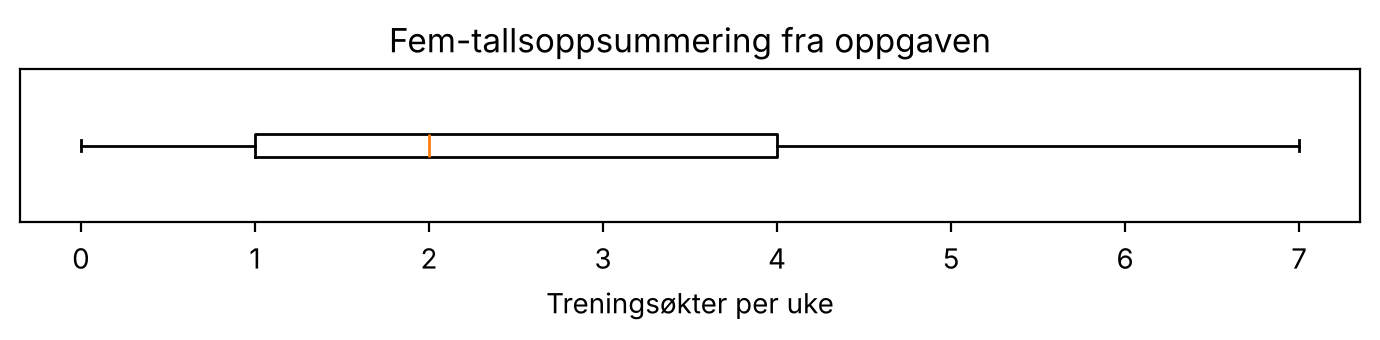

In [3]:
mn, q1, med, q3, mx = 0, 1, 2, 4, 7
sjekk("Kvartilbredde Q3 - Q1", q3 - q1, 3)
print("Høyre værhår:", mx - q3, " venstre værhår:", q1 - mn, "-> høyreskjevt")

fig, ax = plt.subplots(figsize=(7, 1.8))
ax.bxp([{"whislo": mn, "q1": q1, "med": med, "q3": q3, "whishi": mx, "fliers": []}],
       orientation="horizontal", showfliers=False)
ax.set_yticks([]); ax.set_xlabel("Treningsøkter per uke"); ax.set_title("Fem-tallsoppsummering fra oppgaven")
plt.tight_layout(); plt.show()

## Seksjon 4 – SPSS-utskrift, krysstabell og kjikvadrattest
### Del 1: Studietimer
Gjennomsnittet er midtpunktet i konfidensintervallet. $SE = s/\sqrt{n}$, varians $= s^2$, og maks = min + variasjonsbredde.

In [4]:
snitt_deltid = (8.67 + 15.83) / 2
se_heltid    = 11.895 / np.sqrt(50)
var_heltid   = 11.895**2
maks_deltid  = 4 + 26
sjekk("Gjennomsnitt deltid", snitt_deltid, 12.25, 0.01)
sjekk("SE heltid", se_heltid, 1.682, 0.01)
sjekk("Varians heltid", var_heltid, 141.49, 0.1)
sjekk("Maks deltid", maks_deltid, 30)

# Kontroll: CI for deltid fra mean og SE (df = 15)
print("Kontroll CI deltid:", snitt_deltid + np.array([-1, 1]) * stats.t.ppf(0.975, 15) * 1.680)

OK  Gjennomsnitt deltid                                     beregnet = 12.2500   fasit = 12.25 (±0.01)
OK  SE heltid                                               beregnet = 1.6822   fasit = 1.682 (±0.01)
OK  Varians heltid                                          beregnet = 141.4910   fasit = 141.49 (±0.1)
OK  Maks deltid                                             beregnet = 30.0000   fasit = 30 (±0.0)
Kontroll CI deltid: [ 8.66916476 15.83083524]


### Del 2 og 3: Krysstabell og kjikvadrattest
Vi rekonstruerer krysstabellen og lar `scipy` regne ut forventede antall og testen.

In [5]:
obs = pd.DataFrame([[4, 24, 7], [7, 23, 6]], index=["Kvinne", "Mann"], columns=list("ABC"))
print(obs, "\n")
boks1 = 47 - 24
boks2 = 7 / 11 * 100
chi2, p, df, forv = stats.chi2_contingency(obs.values, correction=False)
forv = pd.DataFrame(forv, index=obs.index, columns=obs.columns)
boks3 = forv.loc["Kvinne", "C"]
boks4 = 6 / 36 * 100
sjekk("Boks 1 (antall menn i B)", boks1, 23)
sjekk("Boks 2 (% menn innen A)", boks2, 63.6, 0.05)
sjekk("Boks 3 (forventet kvinner i C)", boks3, 6.4, 0.05)
sjekk("Boks 4 (% C innen menn)", boks4, 16.7, 0.05)
print("\nForventede antall:\n", forv.round(2))
print(f"\nPearson chi2 = {chi2:.3f}, df = {df}, p = {p:.3f}, kritisk verdi = {stats.chi2.ppf(0.95, df):.3f}")
print("Beslutning:", "forkast H0" if p < 0.05 else "ikke forkast H0 (ingen påvist sammenheng)")

        A   B  C
Kvinne  4  24  7
Mann    7  23  6 

OK  Boks 1 (antall menn i B)                                beregnet = 23.0000   fasit = 23 (±0.0)
OK  Boks 2 (% menn innen A)                                 beregnet = 63.6364   fasit = 63.6 (±0.05)
OK  Boks 3 (forventet kvinner i C)                          beregnet = 6.4085   fasit = 6.4 (±0.05)
OK  Boks 4 (% C innen menn)                                 beregnet = 16.6667   fasit = 16.7 (±0.05)

Forventede antall:
            A      B     C
Kvinne  5.42  23.17  6.41
Mann    5.58  23.83  6.59

Pearson chi2 = 0.902, df = 2, p = 0.637, kritisk verdi = 5.991
Beslutning: ikke forkast H0 (ingen påvist sammenheng)


## Seksjon 5 – Korrelasjon og regresjonsplott
Korrelasjonsmatrisen er symmetrisk med 1 på diagonalen. For spredningsplottene leser vi av fortegnet på stigningstallet, konstantleddet og $R^2$.

In [6]:
R = pd.DataFrame([[1, .691, .538, .417], [.691, 1, .757, .266],
                  [.538, .757, 1, .209], [.417, .266, .209, 1]],
                 index=["Opptak","Kartlegging","Forkurs","Studietid"],
                 columns=["Opptak","Kartlegging","Forkurs","Studietid"])
sjekk("Sky 1: r(Opptak, Kartlegging)", R.loc["Opptak","Kartlegging"], 0.691, 0.001)
sjekk("Sky 2: r(Forkurs, Forkurs)", R.loc["Forkurs","Forkurs"], 1, 0.001)

fig = {1: dict(b=2.27, a=1.08, R2=0.69), 2: dict(b=-1.69, a=-0.54, R2=0.65)}
print("Negativ korrelasjon:", [k for k, v in fig.items() if v["b"] < 0])
print("Positivt skjæringspunkt:", [k for k, v in fig.items() if v["a"] > 0])
print("Best tilpasning (størst R2):", max(fig, key=lambda k: fig[k]["R2"]))

OK  Sky 1: r(Opptak, Kartlegging)                           beregnet = 0.6910   fasit = 0.691 (±0.001)
OK  Sky 2: r(Forkurs, Forkurs)                              beregnet = 1.0000   fasit = 1 (±0.001)
Negativ korrelasjon: [2]
Positivt skjæringspunkt: [1]
Best tilpasning (størst R2): 1


## Seksjon 6 – Normalfordelinger
### Del 1: Fire kurver
Toppunktet gir $\mu$, og topphøyden $1/(\sigma\sqrt{2\pi})$ gir $\sigma$. Parametrene under er lest av figuren.

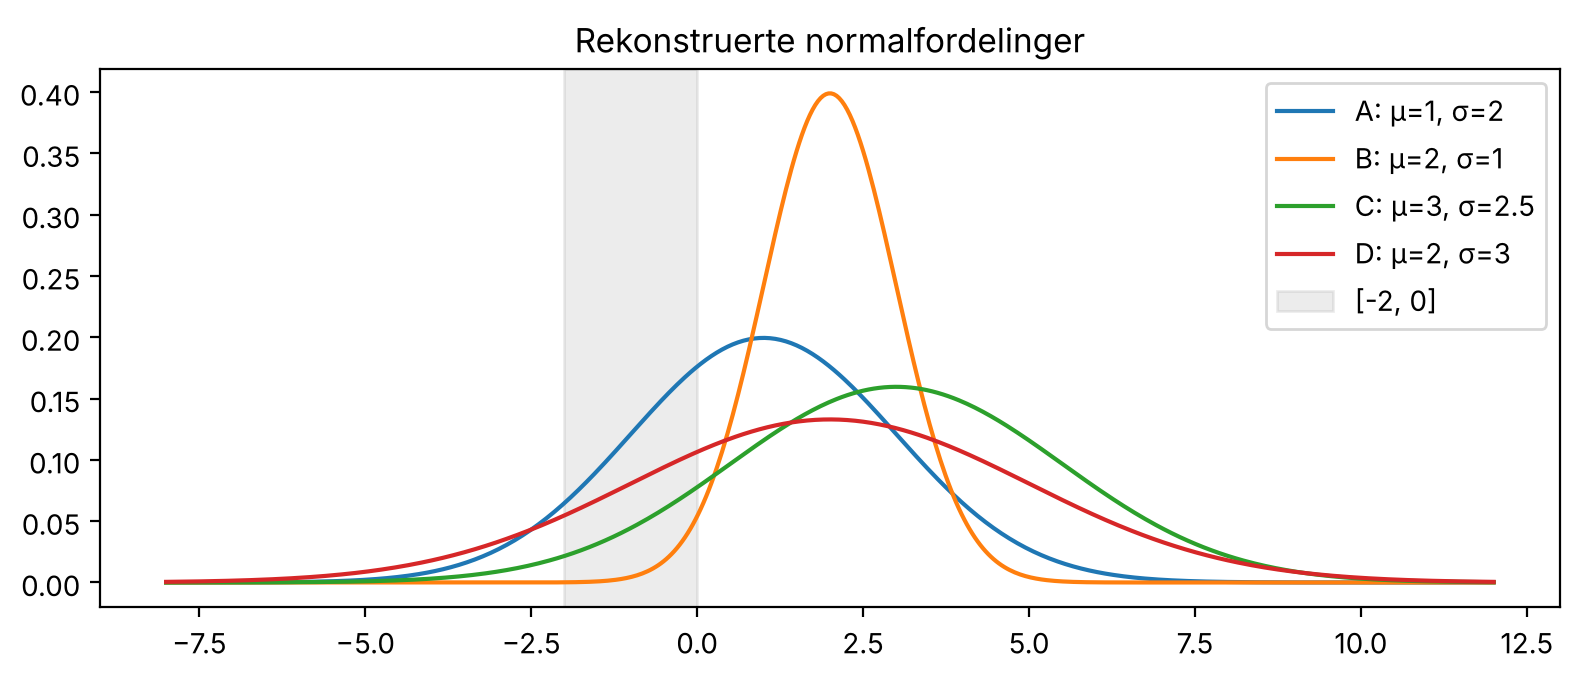

    mu  sigma    topp  P(-2<X<0)
A  1.0    2.0  0.1995     0.2417
B  2.0    1.0  0.3989     0.0227
C  3.0    2.5  0.1596     0.0923
D  2.0    3.0  0.1330     0.1613

Størst μ: C | Minst σ: B | Størst P i [-2,0]: A | μ = 1: A
OK  P(-2 < X < 0) for kurve A                               beregnet = 0.2417   fasit = 0.242 (±0.0005)
OK  P(-2 < X < 0) for kurve D                               beregnet = 0.1613   fasit = 0.161 (±0.0005)


np.True_

In [7]:
kurver = {"A": (1, 2), "B": (2, 1), "C": (3, 2.5), "D": (2, 3)}   # (mu, sigma)
xx = np.linspace(-8, 12, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
for navn, (m, s) in kurver.items():
    ax.plot(xx, stats.norm.pdf(xx, m, s), label=f"{navn}: μ={m}, σ={s}")
ax.axvspan(-2, 0, alpha=0.15, color="grey", label="[-2, 0]")
ax.legend(); ax.set_title("Rekonstruerte normalfordelinger"); plt.tight_layout(); plt.show()

tab = pd.DataFrame({k: {"mu": m, "sigma": s, "topp": stats.norm.pdf(m, m, s),
                        "P(-2<X<0)": stats.norm.cdf(0, m, s) - stats.norm.cdf(-2, m, s)}
                    for k, (m, s) in kurver.items()}).T
print(tab.round(4))
print("\nStørst μ:", tab.mu.idxmax(), "| Minst σ:", tab.sigma.idxmin(),
      "| Størst P i [-2,0]:", tab["P(-2<X<0)"].astype(float).idxmax(),
      "| μ = 1:", tab.index[tab.mu == 1][0])
sjekk("P(-2 < X < 0) for kurve A", tab.loc["A", "P(-2<X<0)"], 0.242, 0.0005)
sjekk("P(-2 < X < 0) for kurve D", tab.loc["D", "P(-2<X<0)"], 0.161, 0.0005)

### Del 2: Betjeningstid, $X \sim N(10, \sigma)$ med $P(X>12) = 0.1587$
$P(Z>1) = 0.1587$ gir $(12-10)/\sigma = 1$, altså $\sigma = 2$.

In [8]:
z = stats.norm.ppf(1 - 0.1587)
sigma = (12 - 10) / z
print(f"z = {z:.4f}  ->  sigma = {sigma:.3f}")
sjekk("P(X < 10)", stats.norm.cdf(10, 10, 2), 0.5, 0.001)
sjekk("P(8 < X < 12)", 1 - 2 * 0.1587, 0.6826, 0.001)
sjekk("P(8 < X < 12) eksakt", stats.norm.cdf(12, 10, 2) - stats.norm.cdf(8, 10, 2), 0.6826, 0.001)

z = 0.9998  ->  sigma = 2.000
OK  P(X < 10)                                               beregnet = 0.5000   fasit = 0.5 (±0.001)
OK  P(8 < X < 12)                                           beregnet = 0.6826   fasit = 0.6826 (±0.001)
OK  P(8 < X < 12) eksakt                                    beregnet = 0.6827   fasit = 0.6826 (±0.001)


np.True_

## Seksjon 7 – Binomisk fordeling og t-skjorter
### Del 1–2: $X \sim \text{Bin}(5,\ 0.55)$
$E(X) = np$ og $\mathrm{Var}(X) = np(1-p)$.

In [9]:
n, p = 5, 0.55
X = stats.binom(n, p)
pmf = pd.Series(X.pmf(range(n + 1)), index=range(n + 1))
print(pmf.round(4).to_string(), "\n")
sjekk("E(X)", X.mean(), 2.75)
sjekk("Var(X)", X.var(), 1.2375, 0.001)
sjekk("P(X > 3)", X.sf(3), 0.2562, 0.001)
sjekk("P(X = 4)", X.pmf(4), 0.2059, 0.001)
sjekk("P(X <= 1)", X.cdf(1), 0.1312, 0.001)
print("Med de avrundede stolpeverdiene: 0.0185 + 0.1128 =", round(0.0185 + 0.1128, 4), "(innenfor toleransen 0.001)")

0    0.0185
1    0.1128
2    0.2757
3    0.3369
4    0.2059
5    0.0503 

OK  E(X)                                                    beregnet = 2.7500   fasit = 2.75 (±0.0)
OK  Var(X)                                                  beregnet = 1.2375   fasit = 1.2375 (±0.001)
OK  P(X > 3)                                                beregnet = 0.2562   fasit = 0.2562 (±0.001)
OK  P(X = 4)                                                beregnet = 0.2059   fasit = 0.2059 (±0.001)
OK  P(X <= 1)                                               beregnet = 0.1312   fasit = 0.1312 (±0.001)
Med de avrundede stolpeverdiene: 0.0185 + 0.1128 = 0.1313 (innenfor toleransen 0.001)


### Del 3: T-skjorter, $X \sim N(50, 10)$
Summen over 4 dager har $E = 200$ og $SD = 10\sqrt{4} = 20$. Gjennomsnittet over 25 dager har $SE = 10/\sqrt{25} = 2$.

In [10]:
mu, s = 50, 10
sjekk("P(X < 50)", stats.norm.cdf(50, mu, s), 0.50, 0.0001)
sjekk("P(X > 60)", stats.norm.sf(60, mu, s), 0.1587, 0.0001)
sjekk("P(55 < X < 65)", stats.norm.cdf(65, mu, s) - stats.norm.cdf(55, mu, s), 0.2417, 0.0001)
sjekk("P(sum 4 dager < 210)", stats.norm.cdf(210, 4 * mu, s * np.sqrt(4)), 0.6915, 0.0001)
sjekk("P(snitt 25 dager < 46)", stats.norm.cdf(46, mu, s / np.sqrt(25)), 0.0228, 0.0001)

OK  P(X < 50)                                               beregnet = 0.5000   fasit = 0.5 (±0.0001)
OK  P(X > 60)                                               beregnet = 0.1587   fasit = 0.1587 (±0.0001)
OK  P(55 < X < 65)                                          beregnet = 0.2417   fasit = 0.2417 (±0.0001)
OK  P(sum 4 dager < 210)                                    beregnet = 0.6915   fasit = 0.6915 (±0.0001)
OK  P(snitt 25 dager < 46)                                  beregnet = 0.0228   fasit = 0.0228 (±0.0001)


np.True_

Figurene viser arealet for $P(55 < X < 65)$ og hvor forskjellig spredningen er for én dag, en sum og et gjennomsnitt: $\sigma$, $\sigma\sqrt{n}$ og $\sigma/\sqrt{n}$.

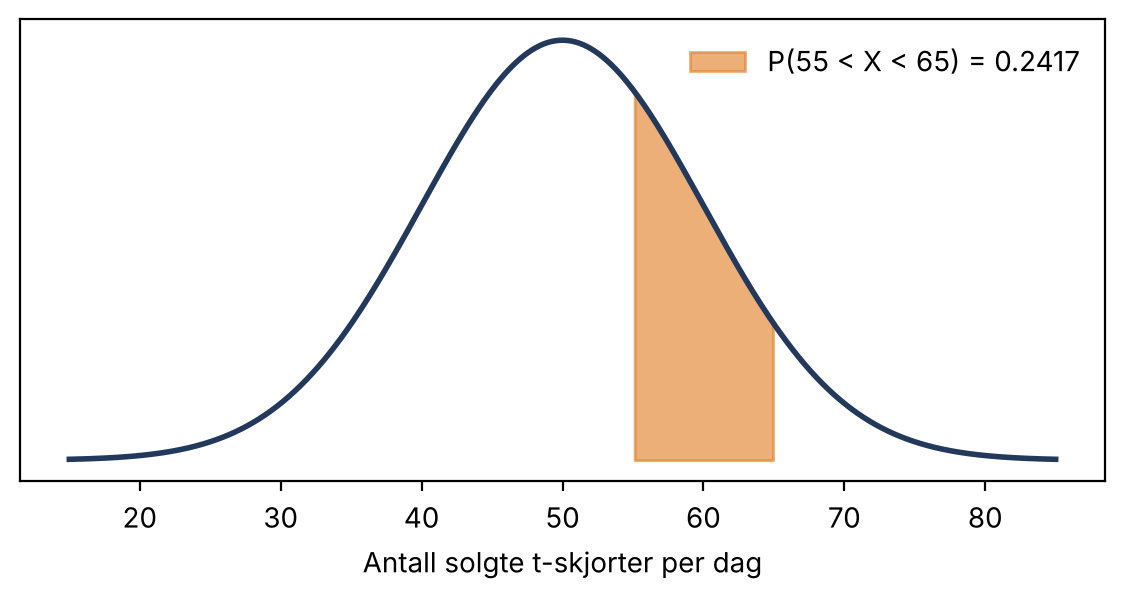

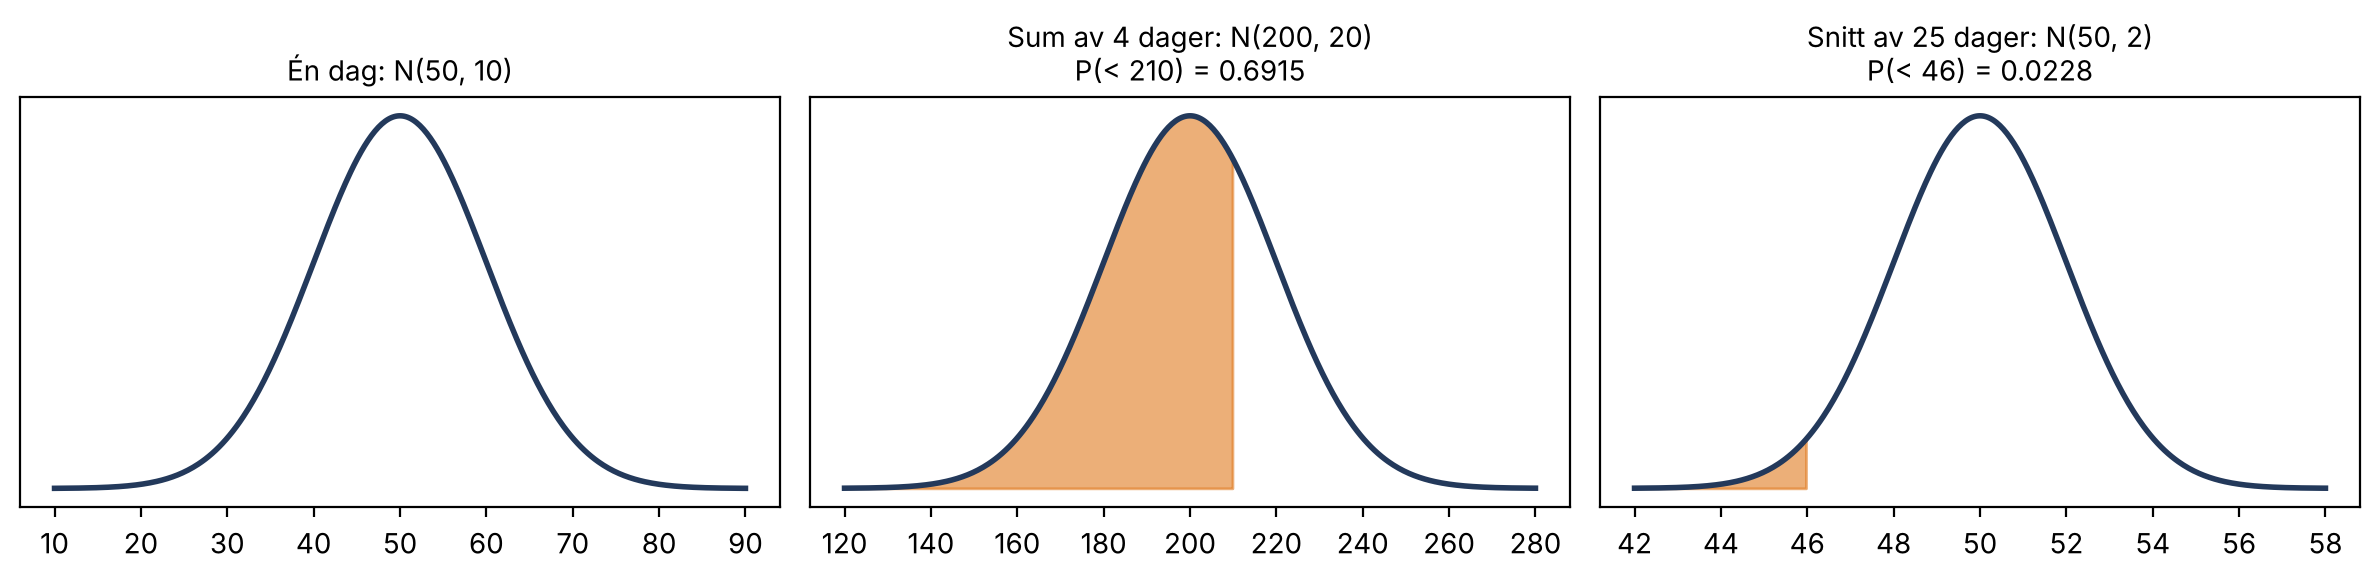

In [11]:
x = np.linspace(15, 85, 500); y = stats.norm.pdf(x, 50, 10)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x, y, color="#23395b", lw=2)
m = (x >= 55) & (x <= 65)
ax.fill_between(x[m], y[m], color="#e07a1f", alpha=0.6, label="P(55 < X < 65) = 0.2417")
ax.set_yticks([]); ax.set_xlabel("Antall solgte t-skjorter per dag"); ax.legend(frameon=False)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, (tittel, mu_, sd_, grense) in zip(axs, [("Én dag: N(50, 10)", 50, 10, None),
                                               ("Sum av 4 dager: N(200, 20)", 200, 20, 210),
                                               ("Snitt av 25 dager: N(50, 2)", 50, 2, 46)]):
    xx = np.linspace(mu_ - 4 * sd_, mu_ + 4 * sd_, 400); yy = stats.norm.pdf(xx, mu_, sd_)
    ax.plot(xx, yy, color="#23395b", lw=2)
    if grense:
        ax.fill_between(xx[xx < grense], yy[xx < grense], color="#e07a1f", alpha=0.6)
        ax.set_title(f"{tittel}\nP(< {grense}) = {stats.norm.cdf(grense, mu_, sd_):.4f}", fontsize=10)
    else:
        ax.set_title(tittel, fontsize=10)
    ax.set_yticks([])
plt.tight_layout(); plt.show()

## Seksjon 8 – Sentralgrenseteoremet
$\bar X \approx N(\mu,\ \sigma/\sqrt n)$ for store $n$, også når populasjonen ikke er normalfordelt. Simuleringen under bruker en skjev populasjon (gammafordeling) med $\mu = 60$, $\sigma = 8$.

OK  E(X-bar)                                                beregnet = 60.0000   fasit = 60 (±0.0)
OK  SE(X-bar)                                               beregnet = 1.0000   fasit = 1 (±0.0)
SE med n = 256: 0.5
OK  P(X-bar > 62)                                           beregnet = 0.0228   fasit = 0.0228 (±0.001)
Simulert: mean = 59.998, sd = 1.002, P(X-bar > 62) = 0.0223


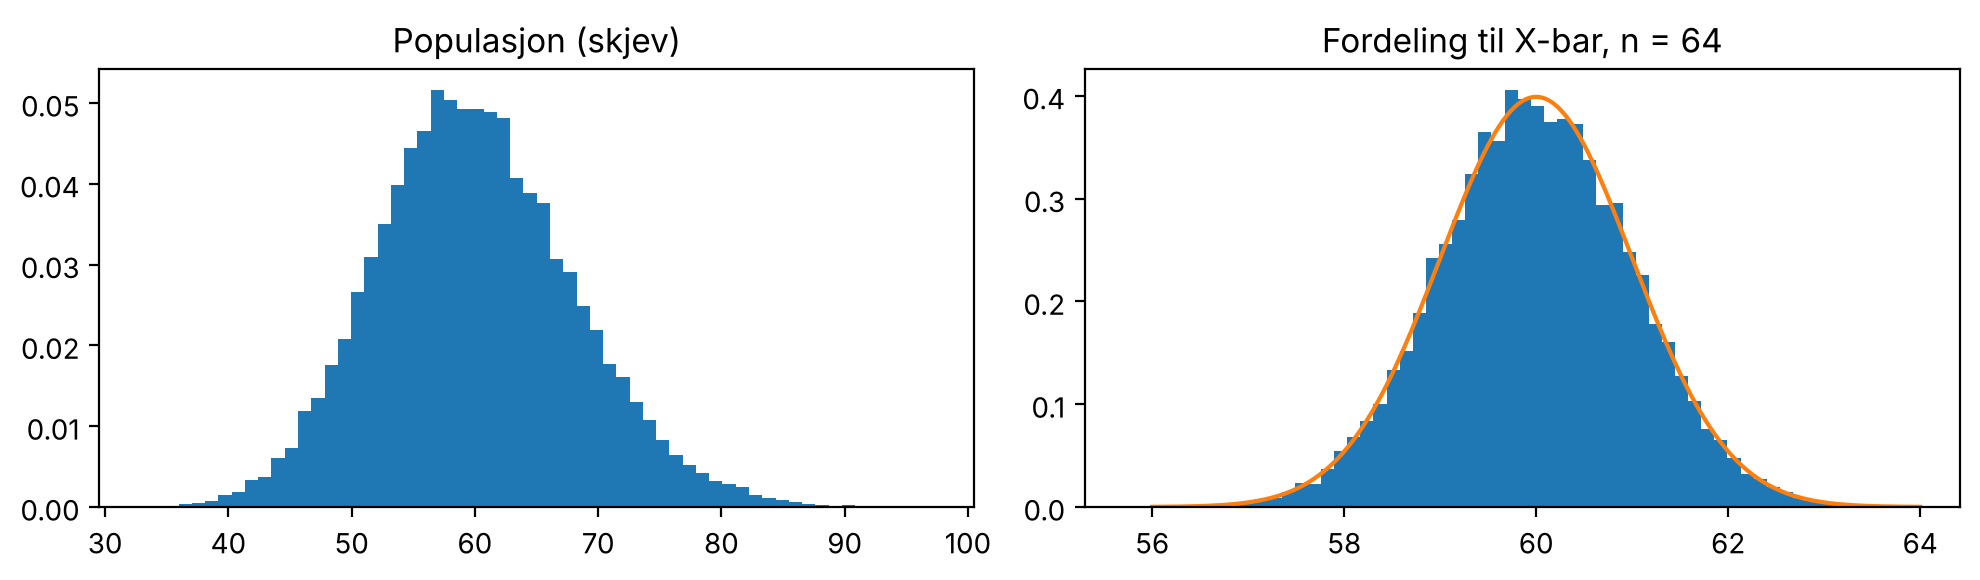

In [12]:
mu, sigma, n = 60, 8, 64
se = sigma / np.sqrt(n)
sjekk("E(X-bar)", mu, 60)
sjekk("SE(X-bar)", se, 1)
print("SE med n = 256:", sigma / np.sqrt(256))
sjekk("P(X-bar > 62)", stats.norm.sf(62, mu, se), 0.0228, 0.001)

# Simulering: skjev populasjon med samme mu og sigma
rng = np.random.default_rng(1)
k = (mu / sigma)**2; theta = sigma**2 / mu
snitt = rng.gamma(k, theta, size=(20000, n)).mean(axis=1)
print(f"Simulert: mean = {snitt.mean():.3f}, sd = {snitt.std():.3f}, P(X-bar > 62) = {(snitt > 62).mean():.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(rng.gamma(k, theta, 20000), bins=60, density=True); ax[0].set_title("Populasjon (skjev)")
ax[1].hist(snitt, bins=60, density=True); g = np.linspace(56, 64, 200)
ax[1].plot(g, stats.norm.pdf(g, mu, se)); ax[1].set_title("Fordeling til X-bar, n = 64")
plt.tight_layout(); plt.show()

## Seksjon 9 og 10 – Valg av metode, p-verdi og type I/II-feil
Disse oppgavene har ingen beregninger. Svarene står i løsningsforslaget. Under er en liten simulering av type I-feilraten: når H0 er sann, forkaster en t-test på 5 %-nivå i om lag 5 % av utvalgene.

In [13]:
rng = np.random.default_rng(2)
p_verdier = np.array([stats.ttest_1samp(rng.normal(0, 1, 30), 0).pvalue for _ in range(5000)])
print(f"Andel forkastet når H0 er sann: {(p_verdier < 0.05).mean():.3f}  (forventet 0.05)")

Andel forkastet når H0 er sann: 0.049  (forventet 0.05)


## Seksjon 11 – t-tester og effektstørrelse
### Del 1: Paret t-test
$T = \bar d / SE$ og tosidig $p = 2 \cdot$ ensidig $p$.

In [14]:
dbar, sd_d, se_d, df = 0.607, 5.080, 0.437, 134
T = dbar / se_d
p2 = 2 * stats.t.sf(abs(T), df)
sjekk("T", T, 1.389, 0.001)
sjekk("Tosidig p", p2, 0.168, 0.001)
print("Kontroll SE = sd/sqrt(n):", sd_d / np.sqrt(df + 1))
print("Konklusjon:", "forkast H0" if p2 < 0.05 else "H0 beholdes")
tq = stats.t.ppf(0.975, df)
sjekk("95 % KI for differansen, nedre", dbar - tq * se_d, -0.257, 0.002)
sjekk("95 % KI for differansen, øvre", dbar + tq * se_d, 1.472, 0.002)
print("Intervallet inneholder 0, som stemmer med at H0 beholdes.")

OK  T                                                       beregnet = 1.3890   fasit = 1.389 (±0.001)
OK  Tosidig p                                               beregnet = 0.1671   fasit = 0.168 (±0.001)
Kontroll SE = sd/sqrt(n): 0.4372167866385262
Konklusjon: H0 beholdes
OK  95 % KI for differansen, nedre                          beregnet = -0.2573   fasit = -0.257 (±0.002)
OK  95 % KI for differansen, øvre                           beregnet = 1.4713   fasit = 1.472 (±0.002)
Intervallet inneholder 0, som stemmer med at H0 beholdes.


### Del 2–4: Uavhengig t-test og Cohens d
Vi regner testen ut på nytt fra gruppestatistikken med `ttest_ind_from_stats`.

In [15]:
n1, m1, s1 = 11, 3.82, 0.603   # Ja
n2, m2, s2 = 60, 3.20, 0.935   # Nei
res_lik = stats.ttest_ind_from_stats(m1, s1, n1, m2, s2, n2, equal_var=True)
res_welch = stats.ttest_ind_from_stats(m1, s1, n1, m2, s2, n2, equal_var=False)
print(f"Lik varians: t = {res_lik.statistic:.3f}, p = {res_lik.pvalue:.3f}")
print(f"Welch:       t = {res_welch.statistic:.3f}, p = {res_welch.pvalue:.3f}")
sjekk("Gjennomsnitt medlemmer", m1, 3.82, 0.01)
sjekk("Antall ikke-medlemmer", n2, 60)
sjekk("Forskjell i gjennomsnitt", m1 - m2, 0.62, 0.01)
sjekk("Tosidig p (lik varians, Levene p = 0.208)", res_lik.pvalue, 0.039, 0.001)

sp = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
d = 0.618 / sp
sjekk("Sammenslått SD (standardiserer)", sp, 0.895, 0.001)
sjekk("Cohens d (med Mean Difference 0.618)", d, 0.691, 0.001)
print("Signifikant på 1 %-nivå?", res_lik.pvalue < 0.01)
# Konfidensintervallet i påstand 2 gjelder forskjellen i gjennomsnitt, ikke enkeltstudenter
se_diff = sp * np.sqrt(1 / n1 + 1 / n2)
tq = stats.t.ppf(0.975, n1 + n2 - 2)
sjekk("95 % KI for forskjellen, nedre", 0.618 - tq * se_diff, 0.033, 0.005)
sjekk("95 % KI for forskjellen, øvre", 0.618 + tq * se_diff, 1.204, 0.005)

Lik varians: t = 2.113, p = 0.038
Welch:       t = 2.841, p = 0.010
OK  Gjennomsnitt medlemmer                                  beregnet = 3.8200   fasit = 3.82 (±0.01)
OK  Antall ikke-medlemmer                                   beregnet = 60.0000   fasit = 60 (±0.0)
OK  Forskjell i gjennomsnitt                                beregnet = 0.6200   fasit = 0.62 (±0.01)
OK  Tosidig p (lik varians, Levene p = 0.208)               beregnet = 0.0382   fasit = 0.039 (±0.001)
OK  Sammenslått SD (standardiserer)                         beregnet = 0.8946   fasit = 0.895 (±0.001)
OK  Cohens d (med Mean Difference 0.618)                    beregnet = 0.6908   fasit = 0.691 (±0.001)
Signifikant på 1 %-nivå? False
OK  95 % KI for forskjellen, nedre                          beregnet = 0.0327   fasit = 0.033 (±0.005)
OK  95 % KI for forskjellen, øvre                           beregnet = 1.2033   fasit = 1.204 (±0.005)


np.True_

## Seksjon 12 – Regresjon

In [16]:
b0, b1 = 0.481, 1.003
sjekk("R2 = SK_reg / SK_tot", 6373.4 / 9349.2, 0.682, 0.001)
sjekk("Prediksjon, forelder 170 cm", b0 + b1 * 170, 170.991, 0.01)

# Multippel: Kroppshoyde = 44.160 + 8.658*Kjonn + 0.679*Foreldrehoyde
c0, cK, cF = 44.160, 8.658, 0.679
pred = lambda kjonn, f: c0 + cK * kjonn + cF * f
sjekk("Mann - kvinne, begge forelder 170 cm", pred(2, 170) - pred(1, 170), 8.658, 0.001)
print("t-verdier: Kjonn =", 5.093, " Foreldrehoyde =", 7.405,
      "\nJustert R2: 0.678 -> 0.752 | standardfeil: 5.988 -> 5.251 cm")

OK  R2 = SK_reg / SK_tot                                    beregnet = 0.6817   fasit = 0.682 (±0.001)
OK  Prediksjon, forelder 170 cm                             beregnet = 170.9910   fasit = 170.991 (±0.01)
OK  Mann - kvinne, begge forelder 170 cm                    beregnet = 8.6580   fasit = 8.658 (±0.001)
t-verdier: Kjonn = 5.093  Foreldrehoyde = 7.405 
Justert R2: 0.678 -> 0.752 | standardfeil: 5.988 -> 5.251 cm


## Seksjon 13 – ANOVA og Levenes test
$F = MS_{\text{mellom}} / MS_{\text{innen}}$ med $(k-1,\ N-k) = (2, 87)$ frihetsgrader.

In [17]:
SSB, SSW, k, N = 1450, 10875, 3, 90
MSB, MSW = SSB / (k - 1), SSW / (N - k)
F = MSB / MSW
pF = stats.f.sf(F, k - 1, N - k)
sjekk("F", F, 5.8, 0.01)
sjekk("p-verdi", pF, 0.004, 0.001)
print(f"df = ({k-1}, {N-k}); total df = {N-1} (fasiten bruker 89)")
print("Levene p = 0.019 < 0.05 -> ulik varians, tolk ANOVA med forsiktighet")

OK  F                                                       beregnet = 5.8000   fasit = 5.8 (±0.01)
OK  p-verdi                                                 beregnet = 0.0043   fasit = 0.004 (±0.001)
df = (2, 87); total df = 89 (fasiten bruker 89)
Levene p = 0.019 < 0.05 -> ulik varians, tolk ANOVA med forsiktighet


## Seksjon 14 – Andelstest og ett-utvalgs t-test
### Del 1: Andelstest ($\alpha = 0.10$)

In [18]:
x_s, phat, se_w = 26, 0.366, 0.057
n_and = x_s / phat
sjekk("n = suksesser / andel", round(n_and), 71)
n_and = 71; phat = x_s / n_and
se_w = np.sqrt(phat * (1 - phat) / n_and)
lower = phat - 1.96 * se_w
sjekk("Nedre grense 95 % Wald-KI", lower, 0.254, 0.001)
sjekk("Øvre grense 95 % Wald-KI", phat + 1.96 * se_w, 0.478, 0.001)
p0 = 0.4
z = (phat - p0) / np.sqrt(p0 * (1 - p0) / n_and)      # score-test
p_and = 2 * stats.norm.sf(abs(z))
print(f"Score-test: z = {z:.3f}, tosidig p = {p_and:.3f} > 0.10 -> ingen påvist endring fra p0 = {p0}")

OK  n = suksesser / andel                                   beregnet = 71.0000   fasit = 71 (±0.0)
OK  Nedre grense 95 % Wald-KI                               beregnet = 0.2541   fasit = 0.254 (±0.001)
OK  Øvre grense 95 % Wald-KI                                beregnet = 0.4783   fasit = 0.478 (±0.001)
Score-test: z = -0.581, tosidig p = 0.561 > 0.10 -> ingen påvist endring fra p0 = 0.4


### Del 2: Ett-utvalgs t-test, $H_0:\ \mu = 10$

In [19]:
n_t, s_t, se_t, mdiff = 70, 18.1195, 2.1657, 2.7786
xbar = 10 + mdiff
df = n_t - 1
t = mdiff / se_t
tkrit = stats.t.ppf(0.975, df)
sjekk("Frihetsgrader", df, 69)
ok = sjekk("Gjennomsnitt i utvalget (fasit 2.78 er feil)", xbar, 2.78, 0.01)
print(f"   -> riktig svar: x-bar = 10 + {mdiff} = {xbar:.2f}")
sjekk("Estimat for sigma (s)", s_t, 18.12, 0.01)
print(f"Kontroll s = SE*sqrt(n) = {se_t*np.sqrt(n_t):.3f}")
print(f"t = {t:.3f}, kritisk verdi t_0.025(69) = {tkrit:.3f} -> t er ikke større (svar 2)")
sjekk("Tosidig p", 2 * stats.t.sf(t, df), 0.204, 0.001)

OK  Frihetsgrader                                           beregnet = 69.0000   fasit = 69 (±0.0)
AVVIK Gjennomsnitt i utvalget (fasit 2.78 er feil)            beregnet = 12.7786   fasit = 2.78 (±0.01)
   -> riktig svar: x-bar = 10 + 2.7786 = 12.78
OK  Estimat for sigma (s)                                   beregnet = 18.1195   fasit = 18.12 (±0.01)
Kontroll s = SE*sqrt(n) = 18.120
t = 1.283, kritisk verdi t_0.025(69) = 1.995 -> t er ikke større (svar 2)
OK  Tosidig p                                               beregnet = 0.2038   fasit = 0.204 (±0.001)


np.True_

## Seksjon 15 – Konfidensintervall og test for sukkerinnhold
Oppgaven gir avrundede t-kvantiler. Vi regner med dem og viser de eksakte for $df = 15$ som kontroll.

{0.1: np.float64(1.341), 0.05: np.float64(1.753), 0.025: np.float64(2.131)} <- eksakte kvantiler, df = 15

OK  90 % KI nedre                                           beregnet = 10.0800   fasit = 10.08 (±0.001)
OK  90 % KI øvre                                            beregnet = 11.5200   fasit = 11.52 (±0.001)
95 % KI: [9.96, 11.64] (bredere). Midtpunkt for alle KI = 10.8
Bredde 90 % KI med n = 16: 1.402
Bredde 90 % KI med n = 64: 0.668
OK  Testobservator T                                        beregnet = 2.0000   fasit = 2.0 (±0.1)
T = 2.00 > t_0.05 = 1.8 -> forkast H0 (svar 2). Eksakt ensidig p = 0.0320


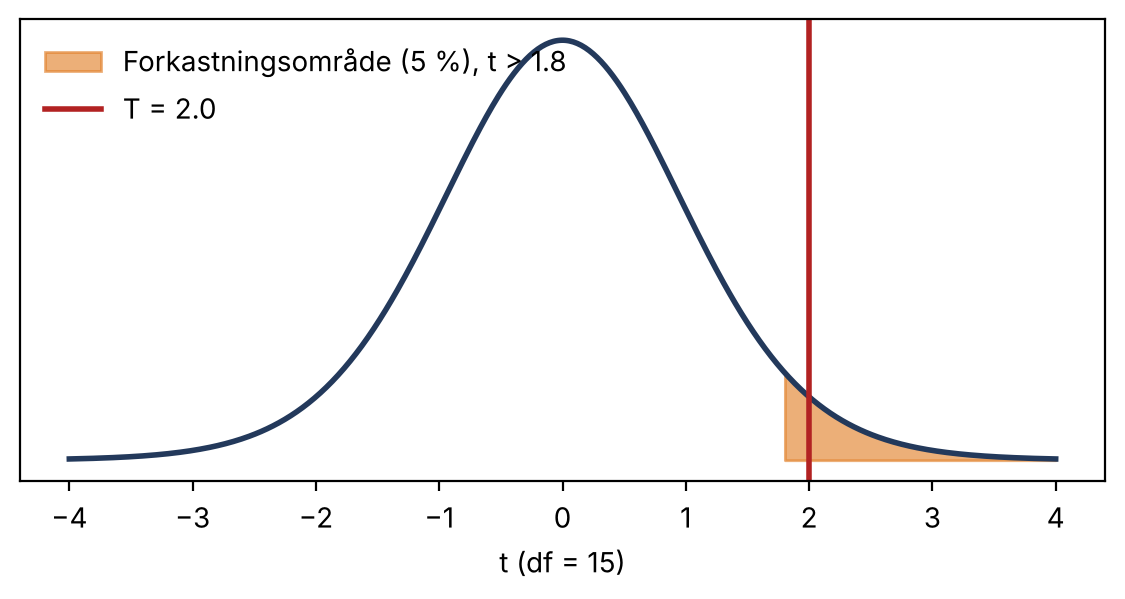

In [20]:
n, xbar, s, mu0 = 16, 10.8, 1.6, 10
se = s / np.sqrt(n)
tq = {0.10: 1.3, 0.05: 1.8, 0.025: 2.1}
print({a: round(stats.t.ppf(1 - a, n - 1), 3) for a in tq}, "<- eksakte kvantiler, df = 15\n")

ki90 = (xbar - tq[0.05] * se, xbar + tq[0.05] * se)
ki95 = (xbar - tq[0.025] * se, xbar + tq[0.025] * se)
sjekk("90 % KI nedre", ki90[0], 10.08, 0.001)
sjekk("90 % KI øvre", ki90[1], 11.52, 0.001)
print(f"95 % KI: [{ki95[0]:.2f}, {ki95[1]:.2f}] (bredere). Midtpunkt for alle KI = {xbar}")
for nn in (16, 64):
    print(f"Bredde 90 % KI med n = {nn}: {2*stats.t.ppf(0.95, nn-1)*s/np.sqrt(nn):.3f}")

T = (xbar - mu0) / se
p1 = stats.t.sf(T, n - 1)
sjekk("Testobservator T", T, 2.0, 0.1)
print(f"T = {T:.2f} > t_0.05 = 1.8 -> forkast H0 (svar 2). Eksakt ensidig p = {p1:.4f}")

t_akse = np.linspace(-4, 4, 500); yt = stats.t.pdf(t_akse, n - 1)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t_akse, yt, color="#23395b", lw=2)
ax.fill_between(t_akse[t_akse >= 1.8], yt[t_akse >= 1.8], color="#e07a1f", alpha=0.6,
                label="Forkastningsområde (5 %), t > 1.8")
ax.axvline(T, color="#b22222", lw=2, label=f"T = {T:.1f}")
ax.set_yticks([]); ax.set_xlabel("t (df = 15)"); ax.legend(frameon=False, loc="upper left")
plt.show()

## Oppsummering
Alle tallsvar er reprodusert. Den eneste AVVIK-linjen kommer fra Seksjon 14: gjennomsnittet i utvalget er 12.78, ikke 2.78 som i fasiten.